In [1]:
import csv
from math import ceil, log
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

N_PRIMES = 750
P_MIN = 31
N_SNAPSHOTS = 200
OUTPUT_DIRECTORY = Path("point_product_plots")

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "savefig.dpi": 200,
})

In [2]:
def first_primes(n):
    if isinstance(n, bool) or not isinstance(n, int) or n < 1:
        raise ValueError('n_primes must be a positive integer')
    limit = 15 if n < 6 else ceil(n * (log(n) + log(log(n)))) + 1
    while True:
        sieve = np.ones(limit + 1, dtype=bool)
        sieve[:2] = False
        for p in range(2, int(limit ** 0.5) + 1):
            if sieve[p]:
                sieve[p * p::p] = False
        primes = np.flatnonzero(sieve)
        if len(primes) >= n:
            return [int(p) for p in primes[:n]]
        limit *= 2

def _trim(poly):
    while poly and poly[-1] == 0:
        poly.pop()
    return poly

def _add(a, b, p):
    return _trim([((a[i] if i < len(a) else 0) + (b[i] if i < len(b) else 0)) % p for i in range(max(len(a), len(b)))])

def _multiply(a, b, p):
    if not a or not b:
        return []
    result = [0] * (len(a) + len(b) - 1)
    for i, x in enumerate(a):
        for j, y in enumerate(b):
            result[i + j] = (result[i + j] + x * y) % p
    return _trim(result)

def _derivative(a, p):
    return _trim([i * a[i] % p for i in range(1, len(a))])

def _gcd(a, b, p):
    a = _trim([x % p for x in a])
    b = _trim([x % p for x in b])
    while b:
        remainder = a[:]
        while len(remainder) >= len(b):
            shift = len(remainder) - len(b)
            factor = remainder[-1] * pow(b[-1], -1, p) % p
            for j, value in enumerate(b):
                remainder[j + shift] = (remainder[j + shift] - factor * value) % p
            _trim(remainder)
        a, b = (b, remainder)
    return a

def _common_root(a, b, p):
    return len(_gcd(a, b, p)) != 1

def _evaluate(coefficients, x, p):
    result = 0
    for coefficient in reversed(coefficients):
        result = (result * x + coefficient) % p
    return result

def smooth_reduction(f, h, p):
    if len(f) > 7 or len(h) > 4:
        raise ValueError('Only the supplied genus-2 models are supported')
    if p != 2:
        discriminant = _add(_multiply(h, h, p), [4 * x % p for x in f], p)
        if _common_root(discriminant, _derivative(discriminant, p), p):
            return False
    else:
        df = _derivative(f, p)
        dh = _derivative(h, p)
        obstruction = _add(_multiply(df, df, p), _multiply(f, _multiply(dh, dh, p), p), p)
        if _common_root(h, obstruction, p):
            return False
    F = list(reversed(f + [0] * (7 - len(f))))
    H = list(reversed(h + [0] * (4 - len(h))))
    if p == 2:
        singular = H[0] % p == 0 and (F[1] ** 2 - H[1] ** 2 * F[0]) % p == 0
    else:
        singular = (H[0] ** 2 + 4 * F[0]) % p == 0 and (2 * H[0] * H[1] + 4 * F[1]) % p == 0
    return not singular

def count_points(f, h, p):
    f6 = f[6] if len(f) > 6 else 0
    h3 = h[3] if len(h) > 3 else 0
    if p == 2:
        affine = sum(((y * y + _evaluate(h, x, p) * y - _evaluate(f, x, p)) % p == 0 for x in range(p) for y in range(p)))
        infinity = sum(((y * y + h3 * y - f6) % p == 0 for y in range(p)))
        return affine + infinity
    if p > 3000000000:
        raise ValueError('Prime is too large for this int64 enumeration')
    x = np.arange(p, dtype=np.int64)
    root_counts = np.zeros(p, dtype=np.int64)
    np.add.at(root_counts, x * x % p, 1)
    h_values = _evaluate(h, x, p)
    discriminants = (h_values * h_values + 4 * _evaluate(f, x, p)) % p
    affine = int(root_counts[discriminants].sum())
    infinity = int(root_counts[(h3 * h3 + 4 * f6) % p])
    return affine + infinity

In [3]:
def _data(x_values, y_values, xmin, xmax):
    x = np.asarray(x_values, dtype=float)
    y = np.asarray(y_values, dtype=float)
    if x.ndim != 1 or y.shape != x.shape or len(x) < 2:
        raise ValueError('Use two equal-length one-dimensional arrays (length >= 2).')
    if not np.all(np.isfinite(x)) or not np.all(np.isfinite(y)):
        raise ValueError('All input values must be finite.')
    if not np.all(np.diff(x) > 0):
        raise ValueError('x_values must be strictly increasing; do not silently sort.')
    a = float(x[0] if xmin is None else xmin)
    b = float(x[-1] if xmax is None else xmax)
    if not (np.isfinite(a) and np.isfinite(b) and (x[0] <= a < b <= x[-1])):
        raise ValueError('Require x_values[0] <= xmin < xmax <= x_values[-1].')
    return (x, y, a, b)

def integral_fit(x_values, y_values, xmin=None, xmax=None):
    x, y, a, b = _data(x_values, y_values, xmin, xmax)
    breaks = np.concatenate(([a], x[(x > a) & (x < b)], [b]))
    left, right = (breaks[:-1], breaks[1:])
    widths = right - left
    midpoints = left + widths / 2
    levels = y[np.searchsorted(x, left, side='right') - 1]
    length = b - a
    center = a + length / 2
    mean_y = float(np.dot(widths, levels) / length)
    slope = float(12 * np.sum(widths * (midpoints - center) * (levels - mean_y)) / length ** 3)
    intercept = mean_y - slope * center
    residual_at_midpoint = levels - (mean_y + slope * (midpoints - center))
    mse = np.sum(widths * (residual_at_midpoint ** 2 + slope ** 2 * widths ** 2 / 12)) / length
    return {'slope': slope, 'intercept': intercept, 'rmse': float(np.sqrt(max(0.0, mse))), 'method': 'exact integral in loglog P', 'n_intervals': len(widths)}

def values_from_counts(primes, counts):
    p = np.asarray(primes, dtype=float)
    counts = np.asarray(counts, dtype=float)
    if p.ndim != 1 or p.shape != counts.shape or len(p) < 2:
        raise ValueError('Use matching prime and count arrays of length >= 2.')
    if not np.all(np.isfinite(p)) or not np.all(np.isfinite(counts)):
        raise ValueError('Primes and counts must be finite.')
    if np.any(p <= 1) or np.any(counts <= 0) or np.any(np.diff(p) <= 0):
        raise ValueError('Require increasing primes > 1 and positive counts.')
    return (np.log(np.log(p)), np.cumsum(np.log1p((counts - p) / p)))

In [4]:
EXAMPLES = [{'number': 1,
  'original_example': 1,
  'label': '440509.a.440509.1',
  'f': [6, 9, 0, -5, -1, 1],
  'h': [1, 1, 0, 1],
  'bad_primes': [440509],
  'jacobian_rank': 4,
  'ns_rank': 1},
 {'number': 2,
  'original_example': 2,
  'label': '277.a.277.1',
  'f': [0, -1, -1],
  'h': [1, 1, 1, 1],
  'bad_primes': [277],
  'jacobian_rank': 0,
  'ns_rank': 1},
 {'number': 3,
  'original_example': 4,
  'label': '400.a.409600.1',
  'f': [1, 0, 4, 0, 4, 0, 1],
  'h': [],
  'bad_primes': [2, 5],
  'jacobian_rank': 0,
  'ns_rank': 3}]

In [5]:
PRIMES = first_primes(N_PRIMES)
P_MAX = PRIMES[-1]
if not 2 <= P_MIN < P_MAX:
    raise ValueError("Require 2 <= P_MIN < the largest computed prime.")
if isinstance(N_SNAPSHOTS, bool) or not isinstance(N_SNAPSHOTS, int) or N_SNAPSHOTS < 2:
    raise ValueError("N_SNAPSHOTS must be an integer >= 2.")

A, B = np.log(np.log([P_MIN, P_MAX]))
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
RESULTS = {}

for example in EXAMPLES:
    primes, counts = [], []
    for p in PRIMES:
        smooth = smooth_reduction(example["f"], example["h"], p)
        if p in example["bad_primes"]:
            if smooth:
                raise ValueError(f"Unexpected smooth reduction for {example['label']} at p={p}.")
            continue
        if not smooth:
            raise ValueError(f"Unexpected singular reduction for {example['label']} at p={p}.")
        n = count_points(example["f"], example["h"], p)
        if n <= 0:
            raise ValueError(f"Nonpositive point count for {example['label']} at p={p}.")
        primes.append(p)
        counts.append(n)

    x, y = values_from_counts(primes, counts)
    fit = integral_fit(x, y, A, B)
    t = np.linspace(A, B, N_SNAPSHOTS)
    cutoff_primes = np.searchsorted(x, t, side="right") - 1
    cutoff_values = y[cutoff_primes]
    cutoffs = np.exp(np.exp(t))
    cutoffs[0], cutoffs[-1] = P_MIN, P_MAX
    expected = example["jacobian_rank"] - example["ns_rank"] + 1
    stem = f"example_{example['number']}_{example['label'].replace('.', '_')}"

    RESULTS[example["number"]] = {
        "example": example,
        "primes": np.asarray(primes, dtype=int),
        "counts": np.asarray(counts, dtype=int),
        "x": x,
        "y": y,
        "fit": fit,
        "t": t,
        "cutoffs": cutoffs,
        "cutoff_values": cutoff_values,
        "expected_exponent": expected,
        "stem": stem,
    }

    with (OUTPUT_DIRECTORY / f"{stem}_counts.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.writer(stream)
        writer.writerow(["prime", "point_count"])
        writer.writerows(zip(primes, counts))

    with (OUTPUT_DIRECTORY / f"{stem}_cutoffs.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.writer(stream)
        writer.writerow(["P", "log_log_P", "log_product"])
        writer.writerows(zip(cutoffs, t, cutoff_values))

with (OUTPUT_DIRECTORY / "numerical_summary.csv").open("w", newline="", encoding="utf-8") as stream:
    writer = csv.writer(stream)
    writer.writerow([
        "example", "lmfdb_label", "expected_exponent", "integral_slope",
        "integral_intercept", "retained_prime_count", "P_min", "P_max",
    ])
    for number, result in RESULTS.items():
        writer.writerow([
            number, result["example"]["label"], result["expected_exponent"],
            result["fit"]["slope"], result["fit"]["intercept"],
            len(result["primes"]), P_MIN, P_MAX,
        ])

In [6]:
def plot_example(number):
    result = RESULTS[number]
    fit = result["fit"]
    fig, ax = plt.subplots(figsize=(6.4, 4.3), layout="constrained")
    ax.plot(
        result["t"], result["cutoff_values"], ".",
        color="#c62d3a", markersize=3.5,
        label=f"{N_SNAPSHOTS} equally spaced snapshots",
    )
    grid = np.linspace(A, B, 300)
    ax.plot(
        grid, fit["intercept"] + fit["slope"] * grid,
        color="#1567a5", linewidth=1.8,
        label=f"Integral fit: {fit['slope']:.4f}",
    )
    ax.set_xlabel(r"$\log\log P$")
    ax.set_ylabel(r"$\log\prod_{p\leq P,\ p\notin S_X}(N_p/p)$")
    ax.set_title(
        f"Example {number} | conjectured exponent {result['expected_exponent']}",
        fontsize=11, pad=9,
    )
    ax.set_xlim(A, B)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.17, linewidth=0.6)
    ax.legend(frameon=False, fontsize=8.5, loc="best")
    fig.savefig(str(OUTPUT_DIRECTORY / f"{result['stem']}.png"))
    plt.show()
    plt.close(fig)

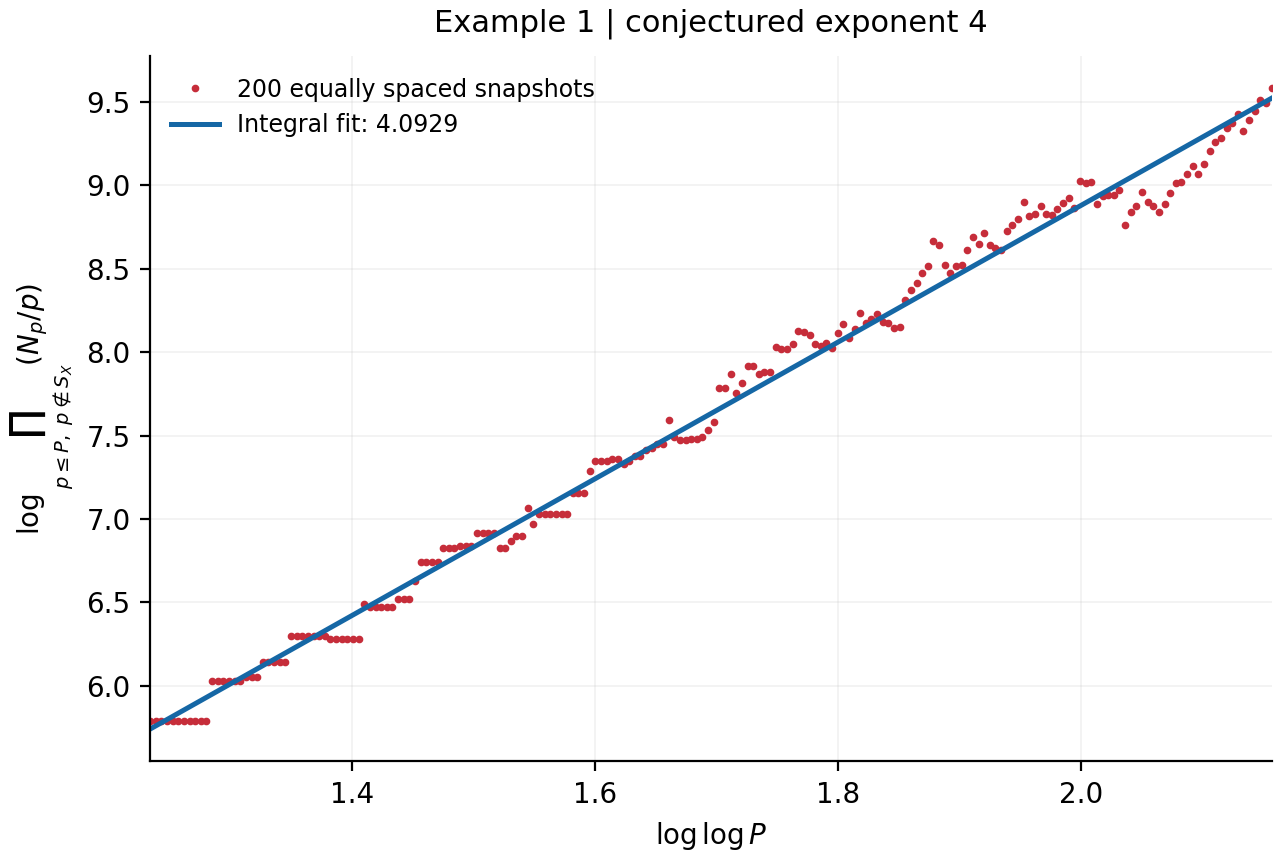

In [7]:
plot_example(1)

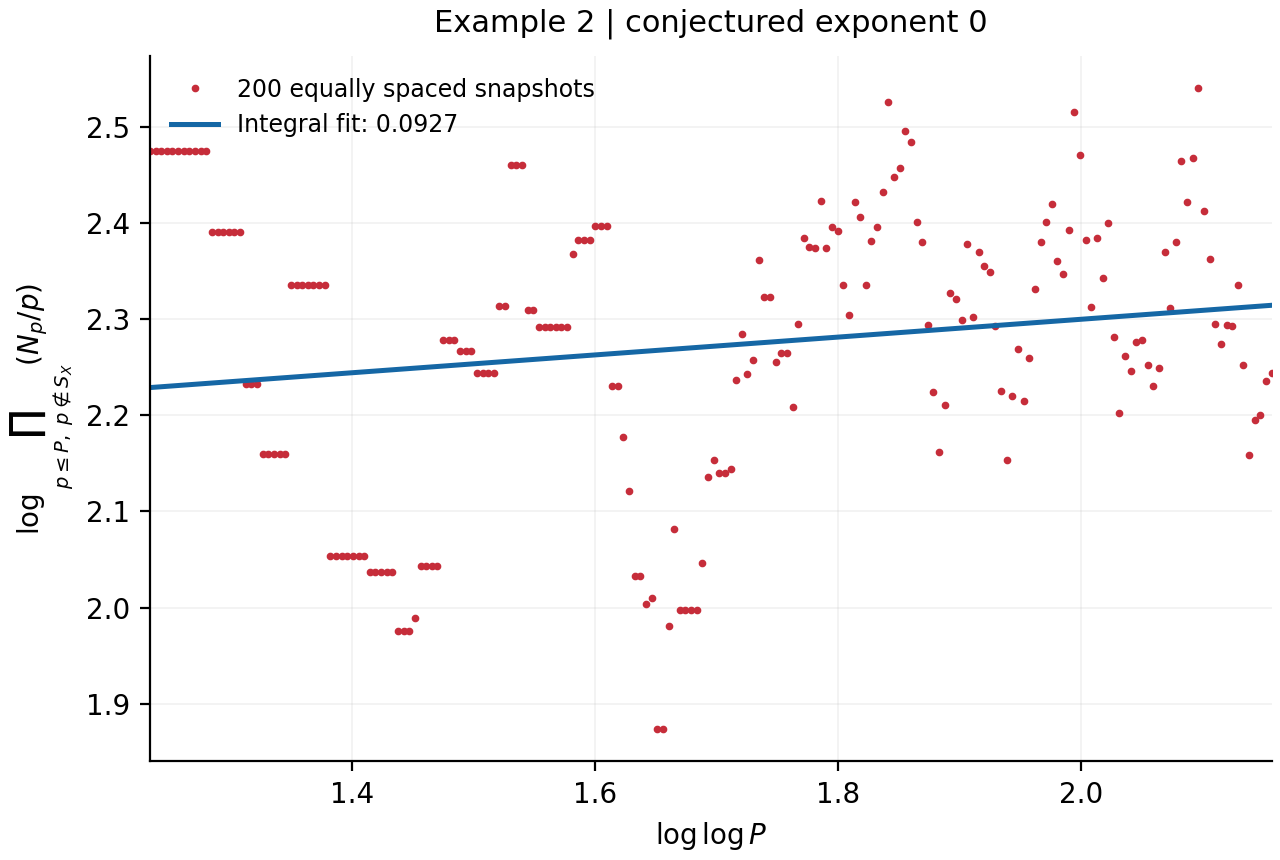

In [8]:
plot_example(2)

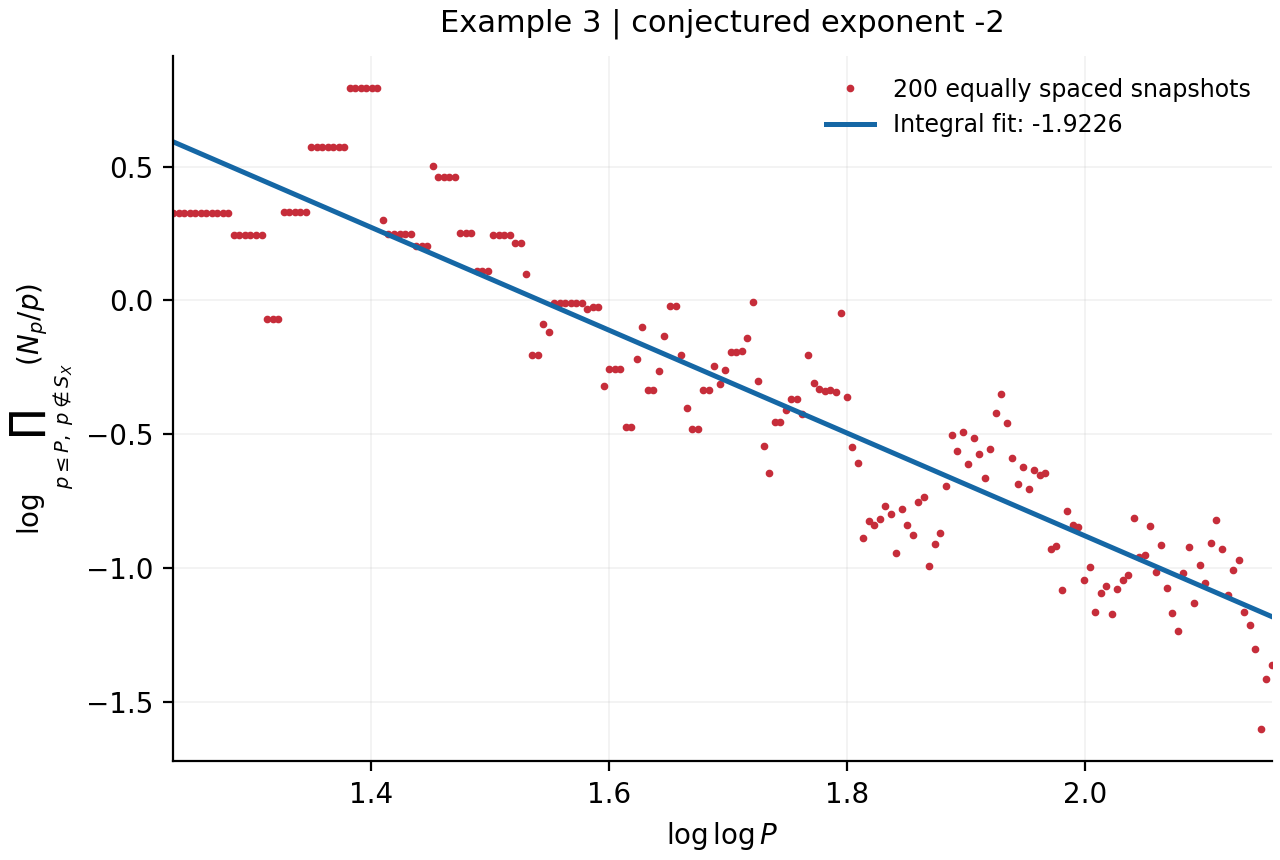

In [9]:
plot_example(3)